# 16 — Mining the recursion direction (Schut §4.1.1 style)

Goal: extract a linear direction $v_\ell$ in residual-stream space such that, **before any body token is generated**, hidden states at positions in the `def`-through-end-of-docstring span separate tasks where greedy decoding ultimately produces recursion from tasks where it produces iteration.

**Setup:**
- **C** = "going to implement recursion" (dynamic concept; unrolls over future tokens)
- **D+** = tasks where `prompt_bias == "neutral"` AND `greedy.strategy == "recursive"` (greedy → recursion under a neutral prompt)
- **D-** = tasks where `prompt_bias == "neutral"` AND `greedy.strategy == "iterative"`
- **Span**: `def` token through closing `"""` of the docstring (inclusive). Strictly pre-body — any direction found here is a *proactiveness* signal by construction.
- **Constraint form**: Schut Eq. 2 — `min ||v||_1  s.t.  v·z+ ≥ v·z-` for many `(d+, t+, d-, t-)` quadruples.
- **Caveats accepted for v0**: function-name / task-identity leakage is allowed (we mimic Schut §4.1.1 looseness). To be revisited if overfitting shows up.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

In [2]:
import os
import sys
import json
import logging

import torch
import transformers

from rich.console import Console
from rich.theme import Theme

from src.utils import logging_utils

os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["CUDA_VISIBLE_DEVICES"] = "1,2,3,4,5,6"

custom_theme = Theme({"default": "white"})
console = Console(theme=custom_theme, highlight=False)

def rich_print(*args, **kwargs):
    console.print(*args, **kwargs)

logging.basicConfig(
    level=logging.INFO,
    format=logging_utils.DEFAULT_FORMAT,
    datefmt=logging_utils.DEFAULT_DATEFMT,
    stream=sys.stdout,
)
logger = logging.getLogger(__name__)
logger.info(f"{torch.__version__=}, {torch.version.cuda=}")
logger.info(f"{transformers.__version__=}")

2026-05-26 17:01:31 __main__ INFO     torch.__version__='2.10.0+cu128', torch.version.cuda='12.8'
2026-05-26 17:01:31 __main__ INFO     transformers.__version__='5.3.0'


In [3]:
from src.models import ModelandTokenizer

MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"

mt = ModelandTokenizer(
    model_key=MODEL_NAME,
    dtype=torch.bfloat16,
    device_map="auto",
    attn_implementation="eager",
)
print(f"n_layer={mt.n_layer}, n_embd={mt.n_embd}, n_heads={mt.model.config.num_attention_heads}")

2026-05-26 17:01:35 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory
2026-05-26 17:01:35 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-05-26 17:01:35 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/config.json "HTTP/1.1 200 OK"
2026-05-26 17:01:35 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
2026-05-26 17:01:35 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/tokenizer_config.json "HTTP/1.1 200 OK"
2026-05-26 17:01:35 httpx INFO     HTT

Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

2026-05-26 17:01:58 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/generation_config.json "HTTP/1.1 307 Temporary Redirect"
2026-05-26 17:01:58 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/generation_config.json "HTTP/1.1 200 OK"
2026-05-26 17:01:58 src.models INFO     loaded model <Qwen/Qwen2.5-Coder-32B-Instruct> | size: 62492.135 MB | dtype: torch.bfloat16 | device: cuda:0
n_layer=64, n_embd=5120, n_heads=40


## 1. Load greedy generations and build D+ / D-

Each JSON under `results/well-known-tasks/generations/<model>/<source>/` is one task. We keep only **neutral-bias** tasks and label each by `greedy.strategy`.

In [4]:
import json
from collections import Counter
from pathlib import Path

import pandas as pd

from src.utils import env_utils

RESULTS_DIR = Path(
    os.path.join(
        env_utils.DEFAULT_RESULTS_DIR,
        "well-known-tasks/generations",
        mt.name.split("/")[-1],
    )
)

records = []
for src_dir in sorted(p for p in RESULTS_DIR.iterdir() if p.is_dir()):
    for fp in sorted(src_dir.glob("*.json")):
        with open(fp) as f:
            records.append(json.load(f))

print(f"Loaded {len(records)} records from {RESULTS_DIR}")
print(f"Sources : {dict(Counter(r['source'] for r in records))}")
print(f"Bias    : {dict(Counter(r['prompt_bias'] for r in records))}")

Loaded 293 records from /disk/u/arnab/Codes/Projects/goals/results/well-known-tasks/generations/Qwen2.5-Coder-32B-Instruct
Sources : {'custom': 176, 'humaneval': 73, 'mbpp': 44}
Bias    : {'neutral': 284, 'recursive': 4, 'iterative': 5}


In [5]:
# D+ / D- by greedy strategy under neutral prompts only
D_plus  = [r for r in records if r["prompt_bias"] == "neutral" and r["greedy"]["strategy"] == "recursive"]
D_minus = [r for r in records if r["prompt_bias"] == "neutral" and r["greedy"]["strategy"] == "iterative"]

print(f"|D+| = {len(D_plus)}  (greedy proactively chose recursion)")
print(f"|D-| = {len(D_minus)} (greedy proactively chose iteration)")

# Quick eyeball of which tasks ended up in each pool
print("\nD+ sample functions:", [r["function_name"] for r in D_plus[:10]])
print("D- sample functions:", [r["function_name"] for r in D_minus[:10]])

|D+| = 29  (greedy proactively chose recursion)
|D-| = 188 (greedy proactively chose iteration)

D+ sample functions: ['ackermann', 'combinations', 'count_and_say', 'count_leaves', 'count_tree_nodes', 'factorial', 'flatten_nested_list', 'invert_binary_tree', 'is_subtree', 'josephus_problem']
D- sample functions: ['add_binary', 'add_two_numbers_linked_list', 'add_without_plus', 'atoi', 'basic_calculator', 'bellman_ford', 'bfs', 'binary_search', 'binary_search_leftmost', 'binary_search_rightmost']


## 2. Span extraction (`def` → closing `"""`)

Find the substring from the first `def ` through the closing `"""` of the docstring, then resolve to a `(start, end)` token range via `find_token_range`.

In [46]:
from src.tokens import find_token_range, prepare_input


def get_span_token_range(record, mt) -> tuple[int, int] | None:
    """(start_token, end_token) inclusive-exclusive for the def→docstring span."""
    prompt = record["prompt"]
    gen = record["greedy"]["extracted_code"]
    full_prompt = prompt + gen

    # print(full_prompt)

    tokenized = prepare_input(
        prompts=full_prompt, tokenizer=mt, return_offsets_mapping=True
    )
    offsets = tokenized.pop("offset_mapping")[0]

    try:
        code_start, _ = find_token_range(
            string=full_prompt, substring="<code>", occurrence=1, tokenizer=mt, offset_mapping=offsets
        )
    except ValueError:
        logger.error(
            f"couldn't find 'def' in the full prompt for function {record['function_name']}"
        )
        return None

    try:
        _, docstring_end = find_token_range(
            string=full_prompt,
            substring='"""',
            tokenizer=mt,
            offset_mapping=offsets,
            occurrence=1,
        )
        # token_span = (def_start, docstring_end)
        # print(
        #     f"{token_span=}: {[mt.tokenizer.decode(t) for t in tokenized.input_ids[0][def_start:docstring_end]]}"
        # )
        return code_start, docstring_end
    except ValueError:
        logger.error(
            f"error parsing docstring in full prompt for function {record['function_name']}"
        )
        return (
            code_start,
            code_start + 5,
        )  # fallback with a reasonable guess for the span end


# Test on one D+ sample
r = D_plus[0]
span = get_span_token_range(r, mt)
print(
    f"task={r['function_name']:<25s} span_tokens={span}  ({span[1] - span[0]} tokens)"
)

base_prompt = r["prompt"]
gen = r["greedy"]["extracted_code"]
full_prompt = base_prompt + gen

tokenized = prepare_input(prompts=full_prompt, tokenizer=mt)
ids = tokenized.input_ids[0].tolist()
decoded_span = [mt.tokenizer.decode([i]) for i in ids[span[0] : span[1]]]
rich_print(f"Tokens in span {span}:", decoded_span)
len(decoded_span)

task=ackermann                 span_tokens=(69, 86)  (17 tokens)


Tokens in span (69, 86):
[
    '\n',
    '<',
    'code',
    '>\n',
    'def',
    ' ack',
    'ermann',
    '(m',
    ',',
    ' n',
    '):\n',
    '   ',
    ' """',
    'Ack',
    'ermann',
    ' function',
    '"""\n'
]

17

In [47]:
import numpy as np

# Filter out records where span extraction fails, attach span to each record
def attach_spans(pool):
    kept = []
    for r in pool:
        span = get_span_token_range(r, mt)
        if span is None:
            continue
        r = dict(r)
        r["_span"] = span  # (start, end) token-index range (end exclusive)
        kept.append(r)
    return kept

D_plus  = attach_spans(D_plus)
D_minus = attach_spans(D_minus)
print(f"After span filtering: |D+|={len(D_plus)}  |D-|={len(D_minus)}")

# Span length distribution — useful sanity check
span_lens = [r["_span"][1] - r["_span"][0] for r in D_plus + D_minus]
print(f"Span length: min={min(span_lens)}  median={int(np.median(span_lens))}  max={max(span_lens)}")

After span filtering: |D+|=29  |D-|=188
Span length: min=12  median=23  max=108


In [48]:
small_spans = [r for r in D_plus + D_minus if (r["_span"][1] - r["_span"][0]) <= 12]
# small_spans[0]

## 3. Extract hidden states across the span, all layers

For each task, one forward pass; slice the full hidden-state tensor at span positions. Store on CPU in fp16.

In [ ]:
from tqdm.auto import tqdm
from src.functional import get_hs

@torch.no_grad()
def get_span_hidden_states(record, mt):
    """Return (n_layer, span_len, n_embd) on CPU in fp16.

    Uses `get_hs` from src.functional: one nnsight trace, fetches every
    (layer, position) pair in the span. Input is
        record['prompt'] + record['greedy']['extracted_code']
    because the closing `\"\"\"` lives in the extracted code; the `_span`
    indices stored on the record were computed against this combined string.

    Leading-dim convention: index `i` = output of `mt.layer_names[i]` (the
    i-th transformer block). Embedding output is NOT included — so layer
    indices here run 0..n_layer-1, unlike model.output_hidden_states which
    runs 0..n_layer (with index 0 = embedding).
    """
    input_text = record["prompt"] + record["greedy"]["extracted_code"]
    tokenized = prepare_input(prompts=input_text, tokenizer=mt)
    start, end = record["_span"]
    positions = list(range(start, end))
    layer_names = mt.layer_names
    locations = [(ly, t) for ly in layer_names for t in positions]
    hs_dict = get_hs(mt=mt, input=tokenized, locations=locations, return_dict=True)
    hs = torch.stack(
        [torch.stack([hs_dict[(ly, t)].detach().to('cpu') for t in positions], dim=0) for ly in layer_names],
        dim=0,
    )
    return hs.to("cpu", dtype=torch.float16)


# Cache hidden states for every task in D+ ∪ D-
for r in tqdm(D_plus,  desc="D+"):
    r["_hs"] = get_span_hidden_states(r, mt)
for r in tqdm(D_minus, desc="D-"):
    r["_hs"] = get_span_hidden_states(r, mt)

example_hs = D_plus[0]["_hs"]
print(f"per-task HS tensor: {tuple(example_hs.shape)}  dtype={example_hs.dtype}")


D+ HS:   0%|          | 0/29 [00:00<?, ?it/s]

D- HS:   0%|          | 0/188 [00:00<?, ?it/s]

per-task HS tensor: (64, 17, 5120)  dtype=torch.float16


## 4. Train / test split by task + constraint sampling

Hold out whole tasks (not individual positions). Sample up to `TRAIN_LIMIT` quadruples `(d+, t+, d-, t-)` for the optimizer.

In [52]:
import random

SEED = 0
TEST_FRAC = 0.2
TRAIN_LIMIT = 10_000  # max constraints fed into the optimizer

rng = random.Random(SEED)

def split_by_task(pool, test_frac, rng):
    idx = list(range(len(pool)))
    rng.shuffle(idx)
    n_test = max(1, int(len(idx) * test_frac))
    test_ix = set(idx[:n_test])
    train = [pool[i] for i in range(len(pool)) if i not in test_ix]
    test  = [pool[i] for i in range(len(pool)) if i     in test_ix]
    return train, test

D_plus_train,  D_plus_test  = split_by_task(D_plus,  TEST_FRAC, rng)
D_minus_train, D_minus_test = split_by_task(D_minus, TEST_FRAC, rng)

print(f"train:  |D+|={len(D_plus_train)}  |D-|={len(D_minus_train)}")
print(f"test :  |D+|={len(D_plus_test)}   |D-|={len(D_minus_test)}")


def sample_constraints(D_pos, D_neg, train_limit, rng):
    """Random quadruples (i, t+, j, t-) — sample, position, sample, position."""
    quads = []
    n_pos, n_neg = len(D_pos), len(D_neg)
    while len(quads) < train_limit:
        i = rng.randrange(n_pos)
        j = rng.randrange(n_neg)
        T_plus  = D_pos[i]["_hs"].shape[1]
        T_minus = D_neg[j]["_hs"].shape[1]
        tp = rng.randrange(T_plus)
        tm = rng.randrange(T_minus)
        quads.append((i, tp, j, tm))
    return quads

train_quads = sample_constraints(D_plus_train, D_minus_train, TRAIN_LIMIT, rng)
print(f"Sampled {len(train_quads)} training constraints")

train:  |D+|=24  |D-|=151
test :  |D+|=5   |D-|=37
Sampled 10000 training constraints


## 5. Optimize direction $v_\ell$ (Schut Eq. 2, hinge-loss, unit-norm)

We modify Schut's exact formulation in two ways:

- **Drop the L1 sparsity term.** L1 prefers basis-aligned directions; we have no reason to expect "going to implement recursion" to align with model bases.
- **Unit-normalize latents and the direction.** All $z^+, z^-$ are L2-normalized per position before training/eval, and we optimize over the unit sphere ($\|v\|=1$). We care about the *direction*, not magnitudes.

Loss (relaxed hinge over the unit sphere):
$$\mathcal{L}(v) = \frac{1}{N}\sum_{(i,t,j,s)} \max\!\Big(0,\, \text{margin} - \hat v \cdot (\hat z^+_{i,t} - \hat z^-_{j,s})\Big), \qquad \hat v = v / \|v\|.$$

Margin is in cosine-similarity scale now, so a much smaller value (~0.05–0.2) is appropriate.

In [69]:
def stack_at_layer(pool, layer_idx, normalize: bool = True):
    """List of (T_i, d) tensors at *layer_idx*, optionally L2-normalized per position.

    Default is `normalize=True`: each position-row has unit L2 norm. This is
    the convention used throughout training, evaluation, and visualization in
    this notebook — we mine direction, not magnitude.
    """
    out = []
    for r in pool:
        h = r["_hs"][layer_idx].to(torch.float32)
        if normalize:
            h = h / (h.norm(dim=-1, keepdim=True) + 1e-9)
        out.append(h)
    return out


def optimize_direction(
    pos_hs_list,   # list of (T_i, d) tensors — pre-normalized
    neg_hs_list,
    quads,         # list of (i, t+, j, t-)
    *,
    margin: float = 0.1,
    lr: float = 1e-2,
    n_steps: int = 2000,
    batch_size: int = 1024,
    seed: int = 0,
    device: str = "cuda",
    verbose: bool = True,
    random_init: bool = False,
):
    """Optimize a unit direction v on the sphere via hinge loss.

    We parameterize the free vector and normalize inside the forward pass
    (``v_unit = v / ||v||``); the returned vector is unit-norm on CPU.

    Initialization:
      - random_init=False (default): warm-start from mean(Z+) - mean(Z-).
        Faster convergence for real runs but, on shuffled-label controls,
        the warm start can carry leaked class signal whenever the random
        train split is class-imbalanced.
      - random_init=True: initialize v as a random unit vector seeded by
        `seed`. Use this for the sanity-check / shuffled-label run.

    Returns (v_unit on CPU, history dict).
    """
    d = pos_hs_list[0].shape[-1]

    # Pre-stack the (z+, z-) pairs for all constraints (faster than indexing per step)
    Zp = torch.stack([pos_hs_list[i][tp] for (i, tp, _, _) in quads]).to(device)
    Zn = torch.stack([neg_hs_list[j][tm] for (_, _, j, tm) in quads]).to(device)
    diffs = (Zp - Zn).contiguous()  # (N, d)
    N = diffs.shape[0]

    if random_init:
        g = torch.Generator(device=device).manual_seed(seed)
        init = torch.randn(d, generator=g, device=device)
    else:
        init = Zp.mean(dim=0) - Zn.mean(dim=0)
    v = (init / (init.norm() + 1e-9)).clone().detach().requires_grad_(True)
    opt = torch.optim.Adam([v], lr=lr)

    hist = {"loss": [], "sat": []}
    for step in range(n_steps):
        idx = torch.randint(0, N, (batch_size,), device=device)
        b = diffs[idx]                                  # (B, d)
        v_unit = v / (v.norm() + 1e-9)
        margins_b = (b * v_unit).sum(dim=-1)            # (B,)
        loss = torch.clamp(margin - margins_b, min=0).mean()

        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()

        if step % max(1, n_steps // 20) == 0 or step == n_steps - 1:
            with torch.no_grad():
                v_u_full = v / (v.norm() + 1e-9)
                full_margins = (diffs * v_u_full).sum(dim=-1)
                sat = (full_margins > 0).float().mean().item()
            hist["loss"].append(loss.item())
            hist["sat"].append(sat)
            if verbose:
                print(f"  step {step:5d}  loss={loss.item():.4f}  sat(train)={sat:.3f}")

    v_final = (v / (v.norm() + 1e-9)).detach().cpu()
    return v_final, hist


def mean_diff_direction(pos_hs_list, neg_hs_list):
    """Baseline: unit-normalize(mean(z+) - mean(z-)). Inputs are already unit-normalized."""
    pos_flat = torch.cat([h.reshape(-1, h.shape[-1]) for h in pos_hs_list], dim=0)
    neg_flat = torch.cat([h.reshape(-1, h.shape[-1]) for h in neg_hs_list], dim=0)
    diff = pos_flat.mean(dim=0) - neg_flat.mean(dim=0)
    return diff / (diff.norm() + 1e-9)


In [70]:
TARGET_LAYER = 44   # 0..n_layer-1 (output of mt.layer_names[TARGET_LAYER])
MARGIN       = 0.1  # cosine-similarity scale (latents are unit-normalized)
N_STEPS      = 200
LR           = 1e-2
BATCH_SIZE   = 1024

pos_hs = stack_at_layer(D_plus_train,  TARGET_LAYER)
neg_hs = stack_at_layer(D_minus_train, TARGET_LAYER)

v_opt, opt_hist = optimize_direction(
    pos_hs, neg_hs, train_quads,
    margin=MARGIN,
    lr=LR, n_steps=N_STEPS, batch_size=BATCH_SIZE,
)
v_md = mean_diff_direction(pos_hs, neg_hs)
print(f"v_opt  ||v||_2={v_opt.norm():.4f}   (should be 1.0)")
print(f"v_md   ||v||_2={v_md.norm():.4f}    (should be 1.0)")
print(f"cos(v_opt, v_md) = {(v_opt @ v_md).item():.3f}")


  step     0  loss=0.0558  sat(train)=0.856
  step    10  loss=0.0335  sat(train)=0.963
  step    20  loss=0.0311  sat(train)=0.940
  step    30  loss=0.0313  sat(train)=0.960
  step    40  loss=0.0313  sat(train)=0.960
  step    50  loss=0.0294  sat(train)=0.963
  step    60  loss=0.0300  sat(train)=0.960
  step    70  loss=0.0297  sat(train)=0.954
  step    80  loss=0.0291  sat(train)=0.962
  step    90  loss=0.0295  sat(train)=0.954
  step   100  loss=0.0286  sat(train)=0.962
  step   110  loss=0.0301  sat(train)=0.961
  step   120  loss=0.0308  sat(train)=0.958
  step   130  loss=0.0294  sat(train)=0.963
  step   140  loss=0.0314  sat(train)=0.958
  step   150  loss=0.0317  sat(train)=0.961
  step   160  loss=0.0313  sat(train)=0.964
  step   170  loss=0.0299  sat(train)=0.964
  step   180  loss=0.0318  sat(train)=0.959
  step   190  loss=0.0291  sat(train)=0.962
  step   199  loss=0.0297  sat(train)=0.962
v_opt  ||v||_2=1.0000   (should be 1.0)
v_md   ||v||_2=1.0000    (should be 

## 6. Detection accuracy on held-out tasks

Two views:
1. **Constraint satisfaction**: fraction of held-out `(d+, t+, d-, t-)` quadruples where `v·z+ > v·z-`.
2. **Per-position margin**: for each test sample, project all of its span positions onto v and average — does the resulting per-sample scalar separate D+ from D-?

In [71]:
TEST_QUADS_LIMIT = 4000

def constraint_satisfaction(v, D_pos, D_neg, layer_idx, n_quads, rng_seed=1):
    rng_local = random.Random(rng_seed)
    pos = stack_at_layer(D_pos, layer_idx)
    neg = stack_at_layer(D_neg, layer_idx)
    quads = sample_constraints(D_pos, D_neg, n_quads, rng_local)
    diffs = torch.stack([pos[i][tp] - neg[j][tm] for (i, tp, j, tm) in quads])
    margins = (diffs * v).sum(dim=-1)
    return (margins > 0).float().mean().item()


def per_sample_score(v, pool, layer_idx):
    """Mean projection of each sample's span-positions onto v → one scalar per task."""
    hs_list = stack_at_layer(pool, layer_idx)
    return torch.stack([(h * v).sum(dim=-1).mean() for h in hs_list])


for name, v in [("v_opt", v_opt), ("v_md", v_md)]:
    sat_tr = constraint_satisfaction(v, D_plus_train, D_minus_train, TARGET_LAYER, TEST_QUADS_LIMIT, rng_seed=2)
    sat_te = constraint_satisfaction(v, D_plus_test,  D_minus_test,  TARGET_LAYER, TEST_QUADS_LIMIT, rng_seed=3)
    scores_p = per_sample_score(v, D_plus_test,  TARGET_LAYER)
    scores_n = per_sample_score(v, D_minus_test, TARGET_LAYER)
    sep = (scores_p.mean() - scores_n.mean()).item() / (scores_p.std() + scores_n.std() + 1e-6).item()
    print(f"{name}: sat(train)={sat_tr:.3f}  sat(test)={sat_te:.3f}  per-sample sep_d-prime={sep:.2f}")

v_opt: sat(train)=0.956  sat(test)=0.931  per-sample sep_d-prime=1.50
v_md: sat(train)=0.727  sat(test)=0.711  per-sample sep_d-prime=0.87


## 7. Layer sweep

Sweep across `LAYERS_TO_SWEEP`; refit `v_opt` at each, report train/test satisfaction. Plot the curve.

In [72]:
# layer index `i` = output of mt.layer_names[i], so valid range is 0..n_layer-1
LAYERS_TO_SWEEP = list(range(0, mt.n_layer, 4))   # coarse first pass; refine around best

sweep_rows = []
for L in LAYERS_TO_SWEEP:
    pos_hs_L = stack_at_layer(D_plus_train,  L)
    neg_hs_L = stack_at_layer(D_minus_train, L)
    v_L, _ = optimize_direction(
        pos_hs_L, neg_hs_L, train_quads,
        margin=MARGIN,
        lr=LR, n_steps=N_STEPS, batch_size=BATCH_SIZE, verbose=False,
    )
    sat_tr = constraint_satisfaction(v_L, D_plus_train, D_minus_train, L, TEST_QUADS_LIMIT, rng_seed=2)
    sat_te = constraint_satisfaction(v_L, D_plus_test,  D_minus_test,  L, TEST_QUADS_LIMIT, rng_seed=3)
    sweep_rows.append({"layer": L, "sat_train": sat_tr, "sat_test": sat_te, "v": v_L})
    print(f"layer {L:2d}  sat_train={sat_tr:.3f}  sat_test={sat_te:.3f}")

sweep_df = pd.DataFrame([{k: v for k, v in r.items() if k != "v"} for r in sweep_rows])
sweep_df


layer  0  sat_train=0.736  sat_test=0.591
layer  4  sat_train=0.785  sat_test=0.607
layer  8  sat_train=0.841  sat_test=0.689
layer 12  sat_train=0.901  sat_test=0.738
layer 16  sat_train=0.929  sat_test=0.835
layer 20  sat_train=0.942  sat_test=0.823
layer 24  sat_train=0.961  sat_test=0.862
layer 28  sat_train=0.938  sat_test=0.843
layer 32  sat_train=0.949  sat_test=0.873
layer 36  sat_train=0.954  sat_test=0.891
layer 40  sat_train=0.964  sat_test=0.920
layer 44  sat_train=0.961  sat_test=0.938
layer 48  sat_train=0.986  sat_test=0.958
layer 52  sat_train=0.993  sat_test=0.969
layer 56  sat_train=0.994  sat_test=0.942
layer 60  sat_train=0.988  sat_test=0.937


,layer,sat_train,sat_test
0,0,0.73625,0.59100
1,4,0.78500,0.60675
2,8,0.84150,0.68925
3,12,0.90075,0.73775
4,16,0.92875,0.83525
5,20,0.94250,0.82350
6,24,0.96050,0.86175
7,28,0.93850,0.84325
8,32,0.94925,0.87300
9,36,0.95375,0.89150


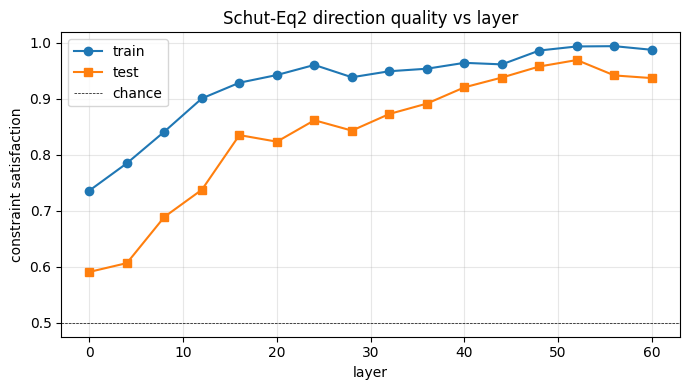

Best test layer: 52


In [73]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sweep_df["layer"], sweep_df["sat_train"], "o-", label="train")
ax.plot(sweep_df["layer"], sweep_df["sat_test"],  "s-", label="test")
ax.axhline(0.5, color="k", lw=0.5, ls="--", label="chance")
ax.set_xlabel("layer"); ax.set_ylabel("constraint satisfaction")
ax.set_title("Schut-Eq2 direction quality vs layer")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

BEST_LAYER = int(sweep_df.loc[sweep_df["sat_test"].idxmax(), "layer"])
print(f"Best test layer: {BEST_LAYER}")

## 8. Per-layer projection analysis (goal axis + residual PC1)

For each swept layer:
- **X-axis (goal)** = $z \cdot v_\ell$, projection of unit-normalized test positions onto the optimized direction $v_\ell$.
- **Y-axis (residual PC1)** = top principal component of $z - (z\cdot v)v$, i.e. variation orthogonal to the goal direction.

We report:
1. **AUC summary across layers** — separability of D+ vs D- along the goal axis and along the residual PC1. A clean goal direction shows high goal-axis AUC and near-chance residual-PC1 AUC.
2. **Animated scatter** — one frame per layer, so we can see when (and how cleanly) the direction crystallizes.

Adapted from `notebooks/03.1_multi_probe.ipynb` §"Contrastive Direction Projection".

 Layer  AUC(goal)  AUC(resid)
 -----  ---------  ----------
     0      0.596       0.521
     4      0.623       0.496
     8      0.694       0.500
    12      0.752       0.497
    16      0.850       0.496
    20      0.832       0.489
    24      0.868       0.497
    28      0.847       0.487
    32      0.879       0.483
    36      0.893       0.483
    40      0.922       0.476
    44      0.937       0.472
    48      0.955       0.471
    52      0.968       0.501
    56      0.942       0.523
    60      0.939       0.502


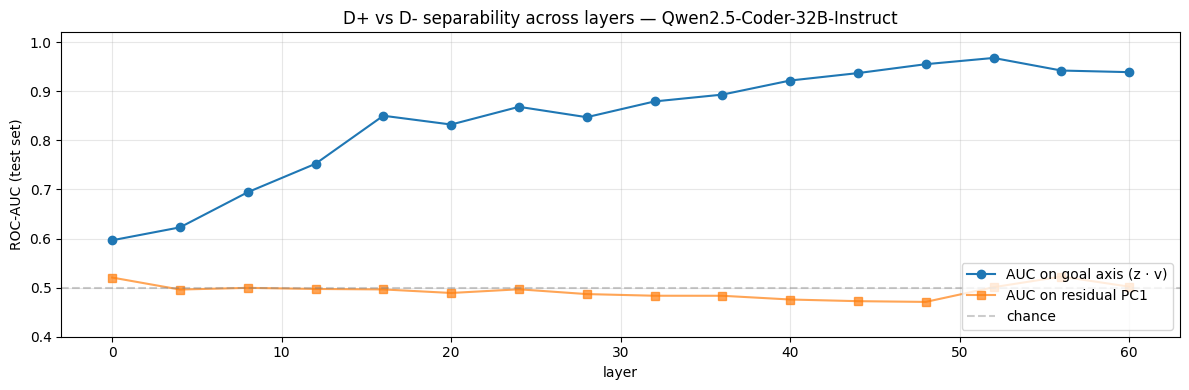

In [74]:
import numpy as np
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score


def flatten_pool(pool, layer_idx, normalize: bool = True):
    """Concatenate every (sample, position) hidden state at *layer_idx*.

    With normalize=True (default), every row is unit-norm — matches the
    convention used in training/eval. We care about directions, not magnitudes.
    """
    rows = []
    for r in pool:
        h = r["_hs"][layer_idx].to(torch.float32).reshape(-1, mt.n_embd)
        if normalize:
            h = h / (h.norm(dim=-1, keepdim=True) + 1e-9)
        rows.append(h)
    return torch.cat(rows, dim=0)


# Per-layer goal + residual-PC1 projections using each layer's optimized v
proj_results: dict[int, dict] = {}
for row in sweep_rows:
    L = row["layer"]
    v = row["v"].numpy()
    z_pos = flatten_pool(D_plus_test,  L).numpy()
    z_neg = flatten_pool(D_minus_test, L).numpy()
    n_pos, n_neg = z_pos.shape[0], z_neg.shape[0]

    all_z = np.concatenate([z_pos, z_neg], axis=0)
    proj_goal = all_z @ v                                    # (N,)
    z_residual = all_z - np.outer(proj_goal, v)              # (N, d)
    proj_residual = PCA(n_components=1).fit_transform(z_residual).squeeze()

    labels = np.concatenate([np.ones(n_pos), np.zeros(n_neg)])
    proj_results[L] = {
        "pos_goal":     proj_goal[:n_pos],
        "neg_goal":     proj_goal[n_pos:],
        "pos_residual": proj_residual[:n_pos],
        "neg_residual": proj_residual[n_pos:],
        "auc_goal":     roc_auc_score(labels, proj_goal),
        "auc_residual": roc_auc_score(labels, proj_residual),
    }

print(f"{'Layer':>6} {'AUC(goal)':>10} {'AUC(resid)':>11}")
print(f"{'-----':>6} {'---------':>10} {'----------':>11}")
for L in sorted(proj_results):
    r = proj_results[L]
    print(f"{L:>6} {r['auc_goal']:>10.3f} {r['auc_residual']:>11.3f}")


# AUC summary across layers
layers_sorted   = sorted(proj_results)
auc_goal_vals   = [proj_results[L]["auc_goal"]     for L in layers_sorted]
auc_resid_vals  = [proj_results[L]["auc_residual"] for L in layers_sorted]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(layers_sorted, auc_goal_vals,  "o-", lw=1.5, label="AUC on goal axis (z · v)")
ax.plot(layers_sorted, auc_resid_vals, "s-", lw=1.5, alpha=0.7, label="AUC on residual PC1")
ax.axhline(0.5, color="gray", ls="--", alpha=0.4, label="chance")
ax.set_xlabel("layer"); ax.set_ylabel("ROC-AUC (test set)")
ax.set_title(f"D+ vs D- separability across layers — {mt.name.split('/')[-1]}")
ax.legend(loc="lower right")
ax.set_ylim(0.4, 1.02)
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()


In [75]:
import matplotlib.animation as animation
from IPython.display import HTML

anim_layers = sorted(proj_results)

all_x = np.concatenate([np.concatenate([proj_results[L]["pos_goal"],     proj_results[L]["neg_goal"]])     for L in anim_layers])
all_y = np.concatenate([np.concatenate([proj_results[L]["pos_residual"], proj_results[L]["neg_residual"]]) for L in anim_layers])
pad_x = (all_x.max() - all_x.min()) * 0.05
pad_y = (all_y.max() - all_y.min()) * 0.05

fig, ax = plt.subplots(figsize=(8, 7))
neg_sc = ax.scatter([], [], alpha=0.3, s=12, c="tab:red",   label="D- (iterative)")
pos_sc = ax.scatter([], [], alpha=0.3, s=12, c="tab:green", label="D+ (recursive)")
ax.legend(markerscale=3, loc="upper left")
ax.set_xlim(all_x.min() - pad_x, all_x.max() + pad_x)
ax.set_ylim(all_y.min() - pad_y, all_y.max() + pad_y)
ax.axvline(0, color="gray", lw=0.5, ls="--", alpha=0.4)
ax.axhline(0, color="gray", lw=0.5, ls="--", alpha=0.4)
ax.set_xlabel("z · v   (goal axis)")
ax.set_ylabel("residual PC1   (z − (z·v)v)")
title = ax.set_title("")

def update(idx):
    L = anim_layers[idx]
    r = proj_results[L]
    pos_sc.set_offsets(np.column_stack([r["pos_goal"], r["pos_residual"]]))
    neg_sc.set_offsets(np.column_stack([r["neg_goal"], r["neg_residual"]]))
    title.set_text(
        f"Layer {L} | recursion direction | {mt.name.split('/')[-1]}\n"
        f"AUC(goal)={r['auc_goal']:.3f}  AUC(resid)={r['auc_residual']:.3f}"
    )
    return pos_sc, neg_sc, title

anim = animation.FuncAnimation(fig, update, frames=len(anim_layers), interval=400, blit=False)
plt.close(fig)
HTML(anim.to_jshtml())


2026-05-26 18:28:41 matplotlib.animation INFO     Animation.save using <class 'matplotlib.animation.HTMLWriter'>


## 9. Negative control — shuffled labels

Sanity floor: if we permute D+/D- labels, the optimizer should fail to find a direction. Anything not crushed by this control is suspicious.

In [76]:
import statistics

N_SHUFFLE_SEEDS = 10

sats = []
for seed in range(N_SHUFFLE_SEEDS):
    rng_shuf = random.Random(100 + seed)
    all_train = D_plus_train + D_minus_train
    rng_shuf.shuffle(all_train)
    half = len(all_train) // 2
    Dp_fake, Dn_fake = all_train[:half], all_train[half:]
    fake_quads = sample_constraints(Dp_fake, Dn_fake, TRAIN_LIMIT, rng_shuf)
    pos_fake = stack_at_layer(Dp_fake, BEST_LAYER)
    neg_fake = stack_at_layer(Dn_fake, BEST_LAYER)
    v_fake, _ = optimize_direction(
        pos_fake, neg_fake, fake_quads,
        margin=MARGIN, lr=LR, n_steps=N_STEPS, batch_size=BATCH_SIZE,
        random_init=True, seed=seed, verbose=False,
    )
    sat = constraint_satisfaction(
        v_fake, D_plus_test, D_minus_test, BEST_LAYER, TEST_QUADS_LIMIT, rng_seed=seed,
    )
    sats.append(sat)
    print(f"  seed {seed:2d}  sat_test={sat:.3f}")

print(
    f"\nshuffled-label sanity (layer {BEST_LAYER}, random init): "
    f"mean={statistics.mean(sats):.3f}  std={statistics.stdev(sats):.3f}  "
    f"min={min(sats):.3f}  max={max(sats):.3f}   (expect ~0.5)"
)


  seed  0  sat_test=0.692
  seed  1  sat_test=0.580
  seed  2  sat_test=0.724
  seed  3  sat_test=0.716
  seed  4  sat_test=0.338
  seed  5  sat_test=0.698
  seed  6  sat_test=0.577
  seed  7  sat_test=0.480
  seed  8  sat_test=0.584
  seed  9  sat_test=0.687

shuffled-label sanity (layer 52, random init): mean=0.608  std=0.124  min=0.338  max=0.724   (expect ~0.5)


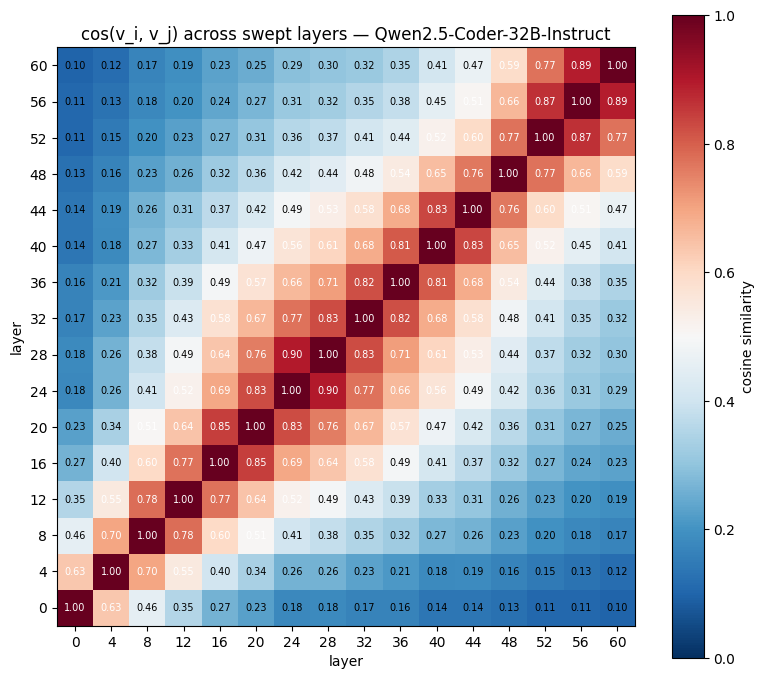

In [84]:
# Pairwise cosine similarity between v's across all swept layers.
# v's are already unit-norm (returned that way from optimize_direction), so
# V @ V.T is the cosine-similarity matrix directly.
import numpy as np

layers_sorted = sorted(r["layer"] for r in sweep_rows)
layer_to_v = {r["layer"]: r["v"] for r in sweep_rows}
V = torch.stack([layer_to_v[L] for L in layers_sorted], dim=0)  # (n_swept, d)
sim = (V @ V.T).numpy()                                        # (n_swept, n_swept)

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(sim, cmap="RdBu_r", vmin=0, vmax=1, origin="lower")
ax.set_xticks(range(len(layers_sorted)))
ax.set_yticks(range(len(layers_sorted)))
ax.set_xticklabels(layers_sorted, rotation=0)
ax.set_yticklabels(layers_sorted)
ax.set_xlabel("layer")
ax.set_ylabel("layer")
ax.set_title(f"cos(v_i, v_j) across swept layers — {mt.name.split('/')[-1]}")
fig.colorbar(im, ax=ax, label="cosine similarity")

# Overlay numeric values when the matrix is small enough to be readable
n = len(layers_sorted)
if n <= 20:
    for i in range(n):
        for j in range(n):
            ax.text(j, i, f"{sim[i, j]:.2f}", ha="center", va="center",
                    color="white" if abs(sim[i, j]) > 0.5 else "black",
                    fontsize=7)

plt.tight_layout(); plt.show()


## 10. Causal validation (TODO)

Once a credible direction is in hand:
- **Steering**: at a span position in a D- task, add $\alpha \cdot v$ to the residual stream across a range of layers and continue greedy decoding. Does the completion flip toward recursion?
- **Suppression**: at a span position in a D+ task, subtract $\alpha \cdot v$. Does the completion flip toward iteration?
- **Anticipatory profile** (§2.2 R-2 of `1_defining_goal.md`): sweep the steering position from early-span → late-span and plot flip rate as a function of $\delta$.

Decide the exact intervention (additive vs replace, layer range, $\alpha$ scan) once we see the v-quality curve from §7.

In [98]:
from src.goals.data import IncompleteCodeSample
from src.goals.functional import supports_chat_template, apply_chat_template
from src.goals.goalscope import greedy_continue
from rich.markup import escape

def get_prompt(sample, mt=mt):
    if supports_chat_template(mt):
        prompt = apply_chat_template(
            mt,
            user_query=sample.full_instruction.strip(),
            incomplete_code=sample.code,
        )
    else:
        prompt = sample.code

    return prompt

# test_sample = IncompleteCodeSample(
#     instruction="Write a C++ function that finds the greatest common divisor of two numbers. Implement it from scratch without using built-in functions.",
#     code='int gcd(int x, int y) {',
#     unit_tests=[],
#     function_name="gcd",
#     prefills=[],
#     augmentation=None,
# )
# test_sample.without_comments = True

# test_sample = IncompleteCodeSample(
#     instruction="Write a C++ function that sorts a list of numbers in ascending order. Implement it from scratch without using built-in sorting functions.",
#     code='void sort(std::vector<int>& numbers) {',
#     unit_tests=[],
#     function_name="sort",
#     prefills=[],
#     augmentation=None,
# )
# test_sample.without_comments = True

# test_sample = IncompleteCodeSample(
#     instruction="Write a C++ function that reverses the characters of a string in place. Implement it from scratch without using built-in functions.",
#     code='void reverse_string(std::string& s) {',
#     function_name="reverse_string",
# )
# test_sample.without_comments = True

# test_sample = IncompleteCodeSample(
#     instruction="Write a C++ function that computes the sum of the decimal digits of a non-negative integer. Implement it from scratch without using built-in functions.",
#     code='int sum_of_digits(int n) {',
#     function_name="sum_of_digits",
# )
# test_sample.without_comments = True

# test_sample = IncompleteCodeSample(
#     instruction="Write a C++ function that converts a non-negative integer to its binary representation as a string. Implement it from scratch without using built-in functions.",
#     code='std::string decimal_to_binary(int n) {',
#     function_name="decimal_to_binary",
# )
# test_sample.without_comments = True

# test_sample = IncompleteCodeSample(
#     instruction="Write a C++ function that computes base raised to the power exp for non-negative integer exponents. Implement it from scratch without using built-in functions.",
#     code='long long power(int base, int exp) {',
#     function_name="power",
# )
# test_sample.without_comments = True

# test_sample = IncompleteCodeSample(
#     instruction="Write a C++ function that counts how many times a target value appears in a list of integers. Implement it from scratch without using built-in functions.",
#     code='int count_occurrences(std::vector<int>& numbers, int target) {',
#     function_name="count_occurrences",
# )
# test_sample.without_comments = True

# test_sample = IncompleteCodeSample(
#     instruction="Write a C++ function that checks whether a string reads the same forwards and backwards. Implement it from scratch without using built-in functions.",
#     code='bool is_palindrome(const std::string& s) {',
#     function_name="is_palindrome",
# )
# test_sample.without_comments = True

# test_sample = IncompleteCodeSample(
#     instruction="Write a C++ function that finds the maximum value in a non-empty list of integers. Implement it from scratch without using built-in functions.",
#     code='int find_max(std::vector<int>& numbers) {',
#     function_name="find_max",
# )
# test_sample.without_comments = True

# test_sample = IncompleteCodeSample(
#     instruction="Write a C++ function that reverses the digits of a non-negative integer. Implement it from scratch without using built-in functions.",
#     code='int reverse_integer(int n) {',
#     function_name="reverse_integer",
# )
# test_sample.without_comments = True

test_sample = IncompleteCodeSample(
    instruction="Write a C++ function that checks whether a number is present in a list of integers sorted in ascending order. The time complexity should be O(log n). Implement it from scratch without using built-in functions.",
    code='bool search(std::vector<int>& numbers, int target) {',
    function_name="search",
)
test_sample.without_comments = True

test_prompt = get_prompt(test_sample, mt)

test_gen = greedy_continue(
    mt,
    **prepare_input(prompts=test_prompt, tokenizer=mt),
    max_new_tokens=256,
)
rich_print(f"[white]{escape(test_prompt)}[/white][bright_yellow]{escape(test_gen)}[/bright_yellow]")

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a C++ function that checks whether a number is present in a list of integers sorted in ascending order. The 
time complexity should be O(log n). Implement it from scratch without using built-in functions. Write your code 
without any comments or explanations, just the implementation.<|im_end|>
<|im_start|>assistant
<code>
bool search(std::vector<int>& numbers, int target) {  
    int left = 0, right = numbers.size() - 1;  
    while (left <= right) {  
        int mid = left + (right - left) / 2;  
        if (numbers[mid] == target) return true;  
        if (numbers[mid] < target) left = mid + 1;  
        else right = mid - 1;  
    }  
    return false;  
}
</code>

In [99]:
from src.functional import get_hs, PatchSpec, generate_with_patch

src_token_range = list(range(-5, 0))  # for normalization
src_hs = get_hs(
    mt=mt,
    input=test_prompt,
    locations=[(layer, t_idx) for layer in mt.layer_names for t_idx in src_token_range],
    return_dict=True,
)

layerwise_src_h_mean = {}
for layer in mt.layer_names:
    hs = torch.stack(
        [src_hs[(layer, t_idx)].to(torch.float32) for t_idx in src_token_range], dim=0
    )
    layerwise_src_h_mean[layer] = hs.mean(dim=0)  # (d,)

In [100]:
V_LAYER = 48
TARGET_LAYERS = list(range(35, 46))
ALPHA = 0.1


patches = []

for li in TARGET_LAYERS:
    src_h_mean = layerwise_src_h_mean[mt.layer_name_format.format(li)]
    src_h_norm = src_h_mean.norm()
    v_L = [row for row in sweep_rows if row["layer"] == V_LAYER][0]["v"].to(
        src_h_norm.device, src_h_mean.dtype
    )
    patches.append(
        PatchSpec(
            location=(mt.layer_name_format.format(li), -1),
            patch=v_L * (ALPHA * src_h_norm / (v_L.norm() + 1e-9)),
            strategy="add",
            on_pass="all",
        )
    )

steered_continuation = generate_with_patch(
    mt=mt,
    inputs=prepare_input(prompts=test_prompt, tokenizer=mt),
    patches=patches,
    max_new_tokens=256,
    patch_interface="baukit",
    remove_prefix=True,
    do_sample=False,
    # n_steer_tokens=20,
)[0]
rich_print(
    f"[white]{escape(test_prompt)}[/white][salmon1]{escape(steered_continuation)}[/salmon1]"
)

<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a C++ function that checks whether a number is present in a list of integers sorted in ascending order. The 
time complexity should be O(log n). Implement it from scratch without using built-in functions. Write your code 
without any comments or explanations, just the implementation.<|im_end|>
<|im_start|>assistant
<code>
bool search(std::vector<int>& numbers, int target) {  
    if (numbers.empty()) return false;  
    if (numbers.size() == 1) return numbers[0] == target;  
    int mid = numbers.size() / 2;  
    if (numbers[mid] == target) return true;  
    if (target < numbers[mid]) return search(numbers.begin(), numbers.begin() + mid, target);  
    else return search(numbers.begin() + mid + 1, numbers.end(), target);  
}
</code>